In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))
import pandas as pd, numpy as np
from IPython.display import Markdown, Image, display
P = ROOT / "data" / "processed"
F = ROOT / "docs" / "figures"
pd.options.display.float_format = "{:,.4f}".format
def table(name): return pd.read_csv(P / name)
def summary(name): return json.loads((P / name).read_text())
def fig(name): display(Image(filename=str(F / name)))
print("Simulated data. Every number below is read from executed pipeline outputs.")


Simulated data. Every number below is read from executed pipeline outputs.


# M2. Competitor and PCW position (Simulated data)

In [2]:
table("m2_overall__simulated_data.csv")

,all,quotes,policies,conversion,avg_rank,mean_median_gap,mean_cheapest_gap,pci,gwp,contribution,margin,contribution_per_quote
0,all,119203,10968,0.0920,4.4846,-0.0180,0.1576,102.5915,"6,352,229.6067","368,645.6346",0.0580,3.0926


In [3]:
table("m2_by_rank__simulated_data.csv")

,our_rank,quotes,policies,conversion,avg_rank,mean_median_gap,mean_cheapest_gap,pci,gwp,contribution,margin,contribution_per_quote
0,1,8960,1768,0.1973,1.0000,-0.1374,-0.0399,116.2535,"854,650.8212","-62,085.4585",-0.0726,-6.9292
1,2,15264,1907,0.1249,2.0000,-0.1039,0.0709,111.8217,"1,003,819.7474","-11,547.6526",-0.0115,-0.7565
2,3,18570,1904,0.1025,3.0000,-0.0745,0.1134,108.2132,"1,046,167.9315","25,689.1441",0.0246,1.3834
3,4,19111,1778,0.0930,4.0000,-0.0458,0.1493,104.8947,"1,027,673.3487","65,027.8422",0.0633,3.4026
4,5,18418,1307,0.0710,5.0000,-0.0016,0.1823,100.2054,"819,631.3111","85,548.0390",0.1044,4.6448
5,6,15843,1014,0.0640,6.0000,0.0456,0.2161,95.7184,"663,257.8416","87,657.0853",0.1322,5.5329
6,7,12009,715,0.0595,7.0000,0.0748,0.2490,93.1669,"498,092.0272","84,857.9226",0.1704,7.0662
7,8,7522,394,0.0524,8.0000,0.1086,0.2878,90.3779,"288,633.9643","56,726.8158",0.1965,7.5415
8,9,3506,181,0.0516,9.0000,0.1493,0.3349,87.2374,"150,302.6137","36,771.8967",0.2447,10.4883


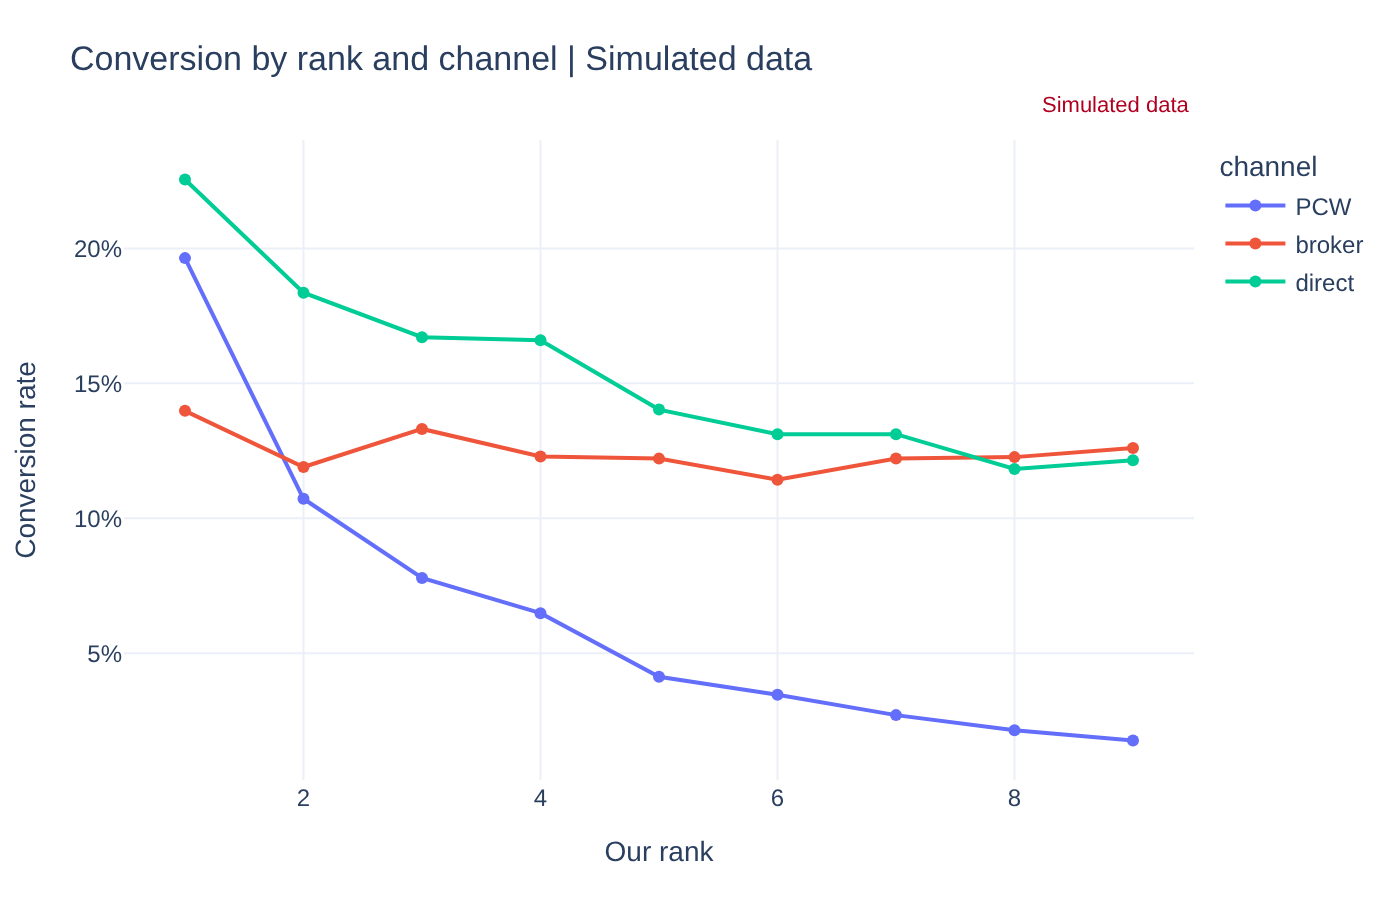

In [4]:
fig("m2_conversion_by_rank_channel__simulated_data.png")

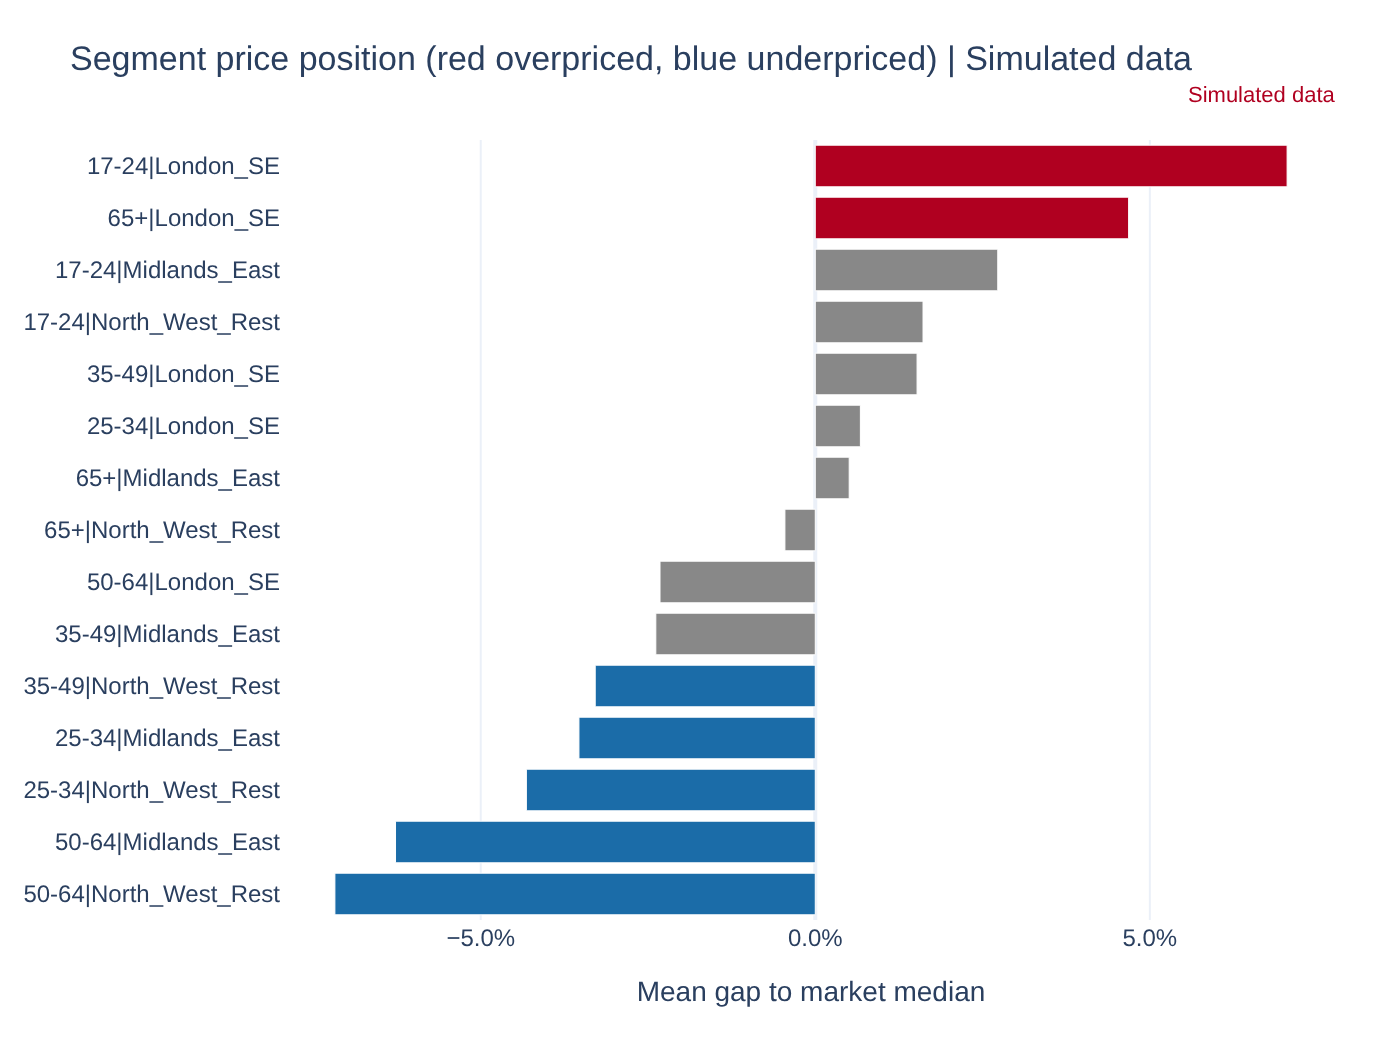

In [5]:
fig("m2_segment_median_gap__simulated_data.png")

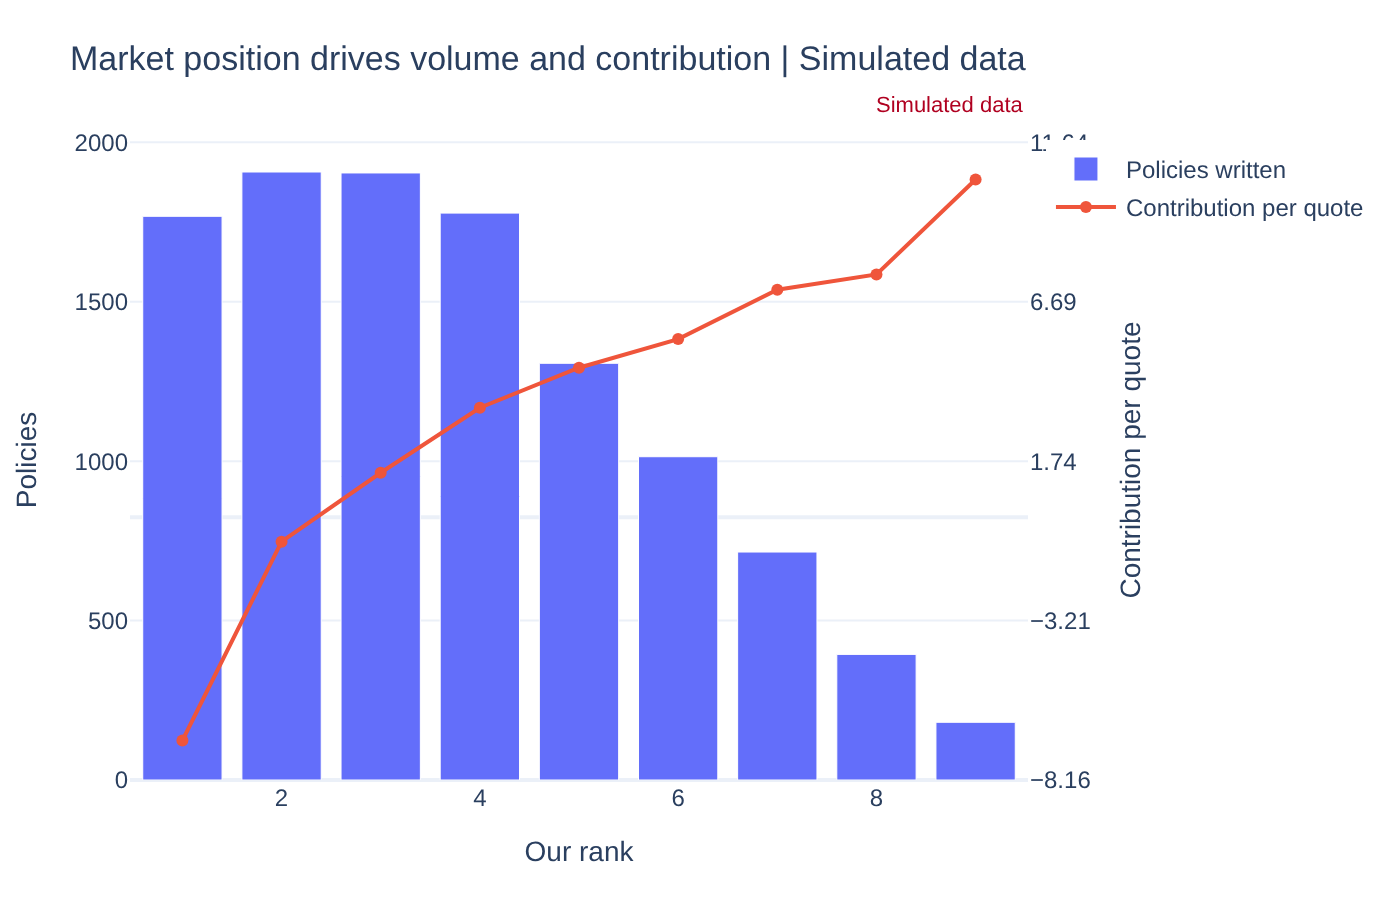

In [6]:
fig("m2_rank_volume_contribution__simulated_data.png")

## Recommendations
Generated by code from the tables above.

In [7]:
display(Markdown((ROOT / "docs" / "competitor_recommendations.md").read_text()))

# Competitor and PCW recommendations

**Simulated data.** Numbers below are produced by `retailpricing.competitor` on the simulated quote table.

Portfolio new business conversion is 9.2% on 119,203 quotes, with an average rank of 4.48 and an average price competitiveness index of 102.6 (100 means we match the market median).

## Market position drives volume
Conversion falls from 19.7% at rank 1 to 5.2% at rank 9. Rank 1 to 3 quotes are 35.9% of volume but write 50.9% of policies.

## Channel
- PCW: conversion 6.7%, average rank 4.48, first-year margin 1.2%.
- broker: conversion 12.4%, average rank 4.52, first-year margin 9.0%.
- direct: conversion 15.7%, average rank 4.48, first-year margin 10.4%.

## Overpriced segments (mean gap to market median at or above the flag threshold)
- 17-24|London_SE: +7.1% to median, conversion 3.3%, first-year margin 27.3%. Margin is above portfolio, so a test discount is the first action to try.
- 65+|London_SE: +4.7% to median, conversion 6.3%, first-year margin 17.7%. Margin is above portfolio, so a test discount is the first action to try.

## Underpriced segments
- 50-64|North_West_Rest: -7.2% to median, conversion 13.1%, first-year margin -9.2%. Margin is below portfolio, so this segment is a candidate for an increase.
- 50-64|Midlands_East: -6.3% to median, conversion 12.6%, first-year margin -6.7%. Margin is below portfolio, so this segment is a candidate for an increase.
- 25-34|North_West_Rest: -4.3% to median, conversion 10.6%, first-year margin 3.7%. Margin is below portfolio, so this segment is a candidate for an increase.
- 25-34|Midlands_East: -3.5% to median, conversion 10.4%, first-year margin 5.9%. Margin is at or above portfolio, so protect volume and monitor.
- 35-49|North_West_Rest: -3.3% to median, conversion 10.1%, first-year margin 1.0%. Margin is below portfolio, so this segment is a candidate for an increase.

These are directional. Module 4 shows observational price effects are biased, so size any move with the randomised test, then use Module 5.
